In [22]:
import sys
RE_path = './RE_Solver/'
sys.path.insert(1, RE_path)

In [51]:
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
import importlib
import RE as RE
importlib.reload(RE)
from unit_conversion import *

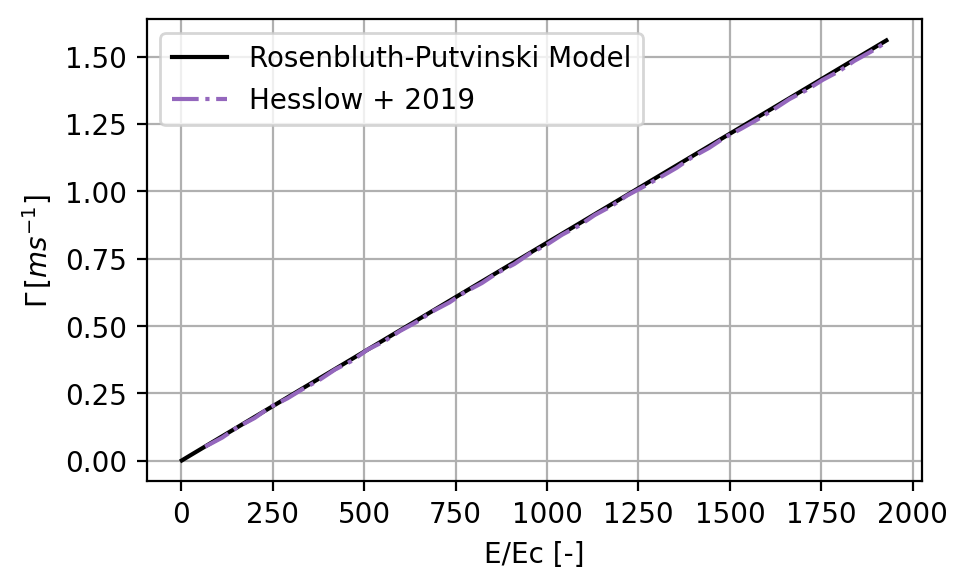

In [52]:
nD = 1e20 # per cubic m
nAr = 0 # per cubic m
zAr = 1
ne  = nD + nAr * zAr
T = 10 # eV
lnA = RE.getCoulombLog(ne,T)
Ec = RE.getConnorHastieField(ne,lnA) # V/m 
# Ec = 1.7
E = np.linspace(0.1,100,100) # V/m
Estar = E / Ec
Z = 1
inv_aspect_ratio = 2/6.2

gamma_RP2 = RE.get_avalance_growth_rate_RP2(Estar,ne,inv_aspect_ratio,lnA,Z) # per s


data = np.loadtxt('./RE_Solver/data/RP_Hesslow_2019.csv',delimiter=',')
fig, axs = plt.subplots(1,1,figsize=(5,3),dpi=200)
axs.plot(E/Ec,gamma_RP2*1e-3,'-',label='Rosenbluth-Putvinski Model',color='black')
axs.plot(data[:,0]/Ec,data[:,1],'-.',label='Hesslow + 2019',color='tab:purple')
axs.set_xlabel('E/Ec [-]')
axs.set_ylabel('$\Gamma \, [ms^{-1}]$')
axs.legend()
axs.grid()


In [53]:
Ec

0.05188246595987291

# Impurity Avalnching Model

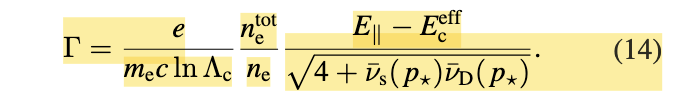

In [25]:
# Input variables
# Epar = [V/m]
# ne = free electron denisty, [per cubic m]
# netot = free + bound electron density, [per cubic m]
# T = Temp. [eV]
# Ec_eff = Effective Critical E-field [V/m]

Epar = np.linspace(0,1000,100) # V/m
netot = 1e20 # free + bound electron density, per cubic m
ne = 1e20 # free electron denisty, per cubic m
Ec_eff = 1.7 # V/m
Z = 1

T = 10 # eV
lnA = RE.getCoulombLog(ne,T)
C = const.e / (const.m_e * const.c * lnA)

nu_s = 1 # Normalized slowing down time
nu_d = 1 + Z # Normalized deflection time

gamma = C * (netot / ne) * (Epar - Ec_eff)/ np.sqrt(4 + nu_s * nu_d) # per s

#### RP Rate ####


gamma_RP = RE.get_avalance_growth_rate_RP2(Epar/getConnorHastieField(ne,lnA),ne,0,lnA,1) # per s

# Plot 
fig, axs = plt.subplots(1,1,figsize=(5,3),dpi=200)
axs.plot(Epar,gamma*1e-3)
axs.plot(Epar,gamma_RP*1e-3,'--',label='RP')
axs.set_xlabel('$E_\parallel$ [V/m]')
axs.set_ylabel('$\Gamma \, [ms^{-1}]$')
axs.grid()





NameError: name 'getConnorHastieField' is not defined

In [26]:
### Functions ####

def calcDelta(Eceff,nuD0,nuS1,tauRadInv,phib1,phib2,pc0):
    return (nuD0/nuS1**2)*(nuD0*tauRadInv/Eceff+phib1+phib2*np.log(pc0))

def calcEceff(delta,nuS0,nuS1,nuD1,nuD0,pc0):
    return nuS0 + nuS1*( (1+nuD1/nuD0)*np.log(pc0) + np.sqrt(2*delta+1))

def getEc_eff(Z,Z0,nj,T,B):
    
    # Returns the effective critical electric field with Ne impurities
    #       Z   : atomic number of each ion species
    #       Z0  : net charge of plasma for each ion species
    #       nj  : density of each ion species [m^(-3)]
    #       Z, Z0 and nj must be arrays of length nSpecies
    #       T   : temperature [eV]  (for calculation of the Coulomb logarithm)
    #       B   : magnetic field [T]
   
    # Constants for Ne
    ln_aBar_Ne = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
    ln_I_Ne = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    ntot = np.sum(Z * nj) # Bound + Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Zfulleff = np.sum(Z**2 * nj)/ne_free 
    lnLStar = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # Coul. Log
    Ne = Z - Z0 # No. of bound electrons

    ## calculate the constants nuD0, nuD1, nuS0, nuS1
    nuD0 = (1 + Zeff) - 2/3 * np.sum(Ne**2 * nj)/ne_free /lnLStar
    nuD1 = Zfulleff/lnLStar
    nuS0 = 1
    nuS1 = (1 + 3 * np.sum(Ne * nj)/ne_free)/(2*lnLStar)
    for i in range(1,Z.shape[0]):
        nuD0 = nuD0 + (Z[i]**2 - Z0[i]**2) * ln_aBar_Ne[Z0[i]] * (nj[i]/ne_free) / lnLStar
        nuS0 = nuS0 + Ne[i] * (-ln_I_Ne[Z0[i]]-1) * (nj[i]/ne_free) / lnLStar

    #### Radiation ####

    # synchrotron radiation term
    tauRadInv =  B**2/(ne_free/1e20)/(15.44*lnLStar);

    # bremsstrahlung term
    ALPHA = 1/137.036;
    bremsprefactor = ALPHA * Zfulleff/lnLStar;
    phib1 = bremsprefactor*0.35;
    phib2 = bremsprefactor*0.20;

    pc0 = nuD0/(2*nuS1);

    Ectot = ntot/ne_free # in units of E_c
    Eceff0 = Ectot
    delta0 = calcDelta(Eceff0,nuD0,nuS1,tauRadInv,phib1,phib2,pc0)
    delta1 = calcDelta(calcEceff(delta0,
                                nuS0,nuS1,nuD1,nuD0,pc0),
                       nuD0,nuS1,tauRadInv,phib1,phib2,pc0)

    EceffOverEctot = calcEceff(delta1,nuS0,nuS1,nuD1,nuD0,pc0)/Ectot
    Ectot =  ntot *  const.e**3  * lnLStar /(4 * np.pi * const.epsilon_0**2 * const.m_e * const.c**2);
    
    return Ectot * EceffOverEctot, Ectot


In [27]:
# Calculating Eeff with Ne impurities

# Inputs
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;
B = 0; 


Ec_eff = getEc_eff(Z,Z0,nj,T,B)

print('Eceff [V/m] = %1.3f\n'%(Ec_eff[0]))
print('Ectot [V/m] = %1.3f\n'%(Ec_eff[1]))


Eceff [V/m] = 0.876

Ectot [V/m] = 0.864



(1e+19, 1e+21)

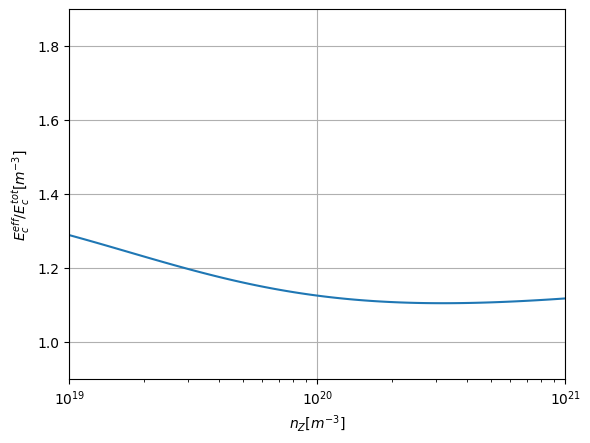

In [28]:
# Calculating Eeff with Ne impurities - vary nz

# Inputs
nz = np.logspace(19,21,100)
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,2]); # Ionization Level
T = 10;
B = 2; 

Ec_eff = np.zeros_like(nz)
for ii in range(nz.shape[0]):
    nj = np.array([1e20,nz[ii]]); # Density
    out = getEc_eff(Z,Z0,nj,T,B)
    Ec_eff[ii] = out[0]/out[1]

plt.plot(nz,Ec_eff)
plt.xscale('log')
plt.ylim([0.9,1.9])
plt.xlabel('$n_Z [m^{-3}]$ ')
plt.ylabel('$E_c^{eff}/E_c^{tot} [m^{-3}]$ ')
plt.grid()
plt.xlim([1e19,1e21])


# Deflection and Slowing Down Frequencies

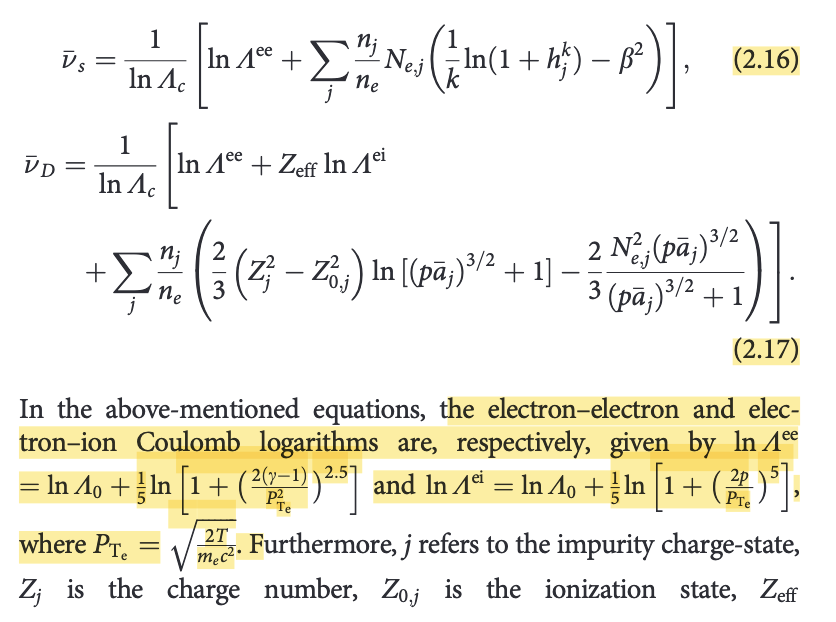

In [29]:
# functions

def get_nuD_nuS(p,Z,Z0,nj,T):
    
    # p = normalized momentum
    # Z = max. ionization
    # Z0 = ionization level
    # nj = density [per cubic m]
    # T = temperature [eV]
    
    # Constants
    ln_aBar_Ne = np.array([4.7064, 4.6097, 4.5028, 4.3858, 4.2638, 4.1266, 3.9568, 3.6810, 3.1777, 3.1278])
    ln_I_Ne = np.array([-8.2227, -8.0370, -7.8614, -7.6837, -7.4994, -7.2788, -6.9808, -6.5976, -5.8933, -5.8320])
    
    
    aBar_Ne = np.exp(ln_aBar_Ne)
    I_Ne = np.exp(ln_I_Ne)
    k = 5
    
    # Other Quantities
    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    Zeff = np.sum((Z0**2 * nj))/ne_free # Effective Ionization
    Ne = Z - Z0 # No. of bound electrons

    # Everything is a function of momentum p
    gamma = np.sqrt(1+p**2)
    beta = p**2 / (1 + p**2)
    
    # Coulomb Logs (also functions of p)
    PT = np.sqrt(2 * T / const.m_e / const.c**2) # Thermal velocity
    lnAc = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # RE-Thermal Coul. log
    lnA0 = 14.9 - 0.5 * np.log(ne_free/1e20) + np.log(T/1e3) # Thermal-Thermal Coul. Log
    lnAee = lnA0 + 1/5 * np.log(1 + (2*(gamma-1)/PT**2)**2.5)
    lnAei = lnA0 + 1/5 * np.log(1 + (2*p/PT)**5)
    # lnAee = lnAc + np.log(np.sqrt(gamma-1))
    # lnAei = lnAc + np.log(np.sqrt(2) * p)
    
    # Caluclate nuS and nuD (Bandaru + 2024)

    nuS = lnAee
    nuD = lnAee + Zeff * lnAei
    for j in range(1,Z.shape[0]):
        hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
        F1j = 1/k * np.log(1+hj**k) - beta**2
        pabar1p5 = (p*aBar_Ne[Z0[j]])**1.5
        nuS = nuS + (nj[j] / ne_free)  * Ne[j] * F1j
        nuD = nuD + (nj[j] / ne_free) * ( 
                      (2/3 * (Z[j]**2 - Z0[j]**2)) * np.log(pabar1p5+1)
                    - (2/3 * Ne[j]**2 * pabar1p5 / (pabar1p5+1))
                    )
#     # Hesslow + 2018    
#     nuS = lnAee
#     nuD = lnAee + Zeff * lnAei
#     for j in range(1,Z.shape[0]):
#         hj = p * np.sqrt(gamma-1) / I_Ne[Z0[j]]
#         nuS = nuS + (nj[j] / ne_free)  * Ne[j] * (np.log(hj) - beta**2)
#         nuD = nuD + (nj[j] / ne_free) * ( 
#                       (Z[j]**2 - Z0[j]**2) * np.log(p*aBar_Ne[Z0[j]])
#                     - 2/3 * Ne[j]**2
#                     )
        
    nuS = nuS / lnAc
    nuD = nuD / lnAc
    
    return nuD, nuS

    
    

In [30]:
# Inputs
p = np.logspace(-1,2,1000)
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([0,1e20]); # Density
T = 10;

nuD, nuS = get_nuD_nuS(p,Z,Z0,nj,T)

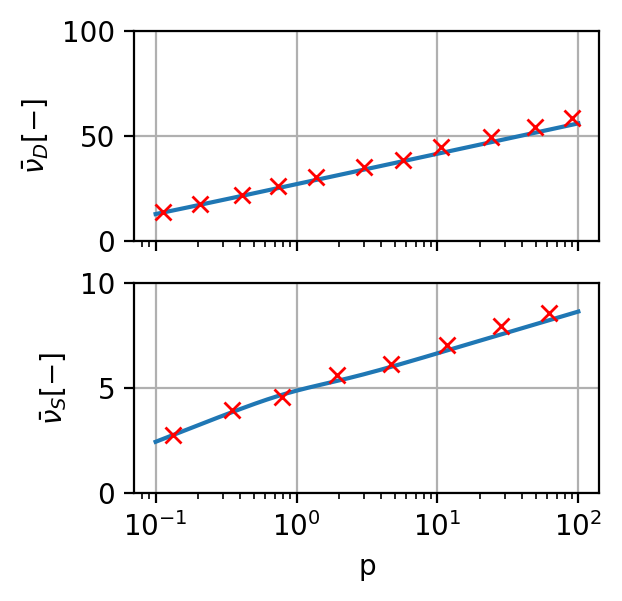

In [31]:
fig, axs = plt.subplots(2,1,dpi=200,sharex=True,figsize=(3,3))

axs[0].plot(p,nuD)
axs[1].plot(p,nuS)

axs[0].set_ylabel('$\\bar{\\nu}_D [-]$')
axs[1].set_ylabel('$\\bar{\\nu}_S [-]$')

for ii in range(axs.shape[0]):
    axs[ii].grid()
    axs[ii].set_xscale('log')
    
axs[-1].set_xlabel('p') 
axs[0].set_ylim([0,100])
axs[1].set_ylim([0,10])


# Compare (Hesslow + 2018 Fig. 1)

data = np.loadtxt(RE_path + '/data/HesslowNenuD.csv',delimiter=',')
axs[0].plot(data[:,0],data[:,1],'rx')

data = np.loadtxt(RE_path + '/data/HesslowNenuS.csv',delimiter=',')
axs[1].plot(data[:,0],data[:,1],'rx')
    

# Find pstar

In [32]:
from scipy.optimize import fsolve

def fn(pstar,E_star,Z,Z0,nj,T):
    # T [eV]
    # Pstar = normalized momentum
    # Estar = Epar / E_CH (E_CH = Connor Hastie Critical Field)
    nuD, nuS = get_nuD_nuS(pstar,Z,Z0,nj,T)
    return pstar * (E_star)**(0.5) - (nuS * nuD)**(1/4)

## Newtons Method ##

def get_pstar(E_star, # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-2, # step for taing numerical derivative
              verbose=False):
    
    thres = 1e-3
    res = 1e3
    ii = 0
    x = 1 * x0
    while ((ii < nmax) and (res>thres)):
        f_x = fn(x,E_star,Z,Z0,nj,T) # value of fn
        fp_x = (fn(x+eps,E_star,Z,Z0,nj,T) 
                - fn(x-eps,E_star,Z,Z0,nj,T)) / (2 * eps) # derivative
        xnew = x - f_x / fp_x
        res = np.abs((xnew - x)/x)
        x = 1* xnew
        ii+=1
    
    if verbose:
        print ('pstar = %1.3f, Iterations = %d, Residual = %1.2g'%(x,ii,fn(x,E_star,Z,Z0,nj,T)))
    
    return x
    
    
    
    
    
    

pstar =  [1.50414915]
pstar = 1.504, Iterations = 3, Residual = -2.4e-11


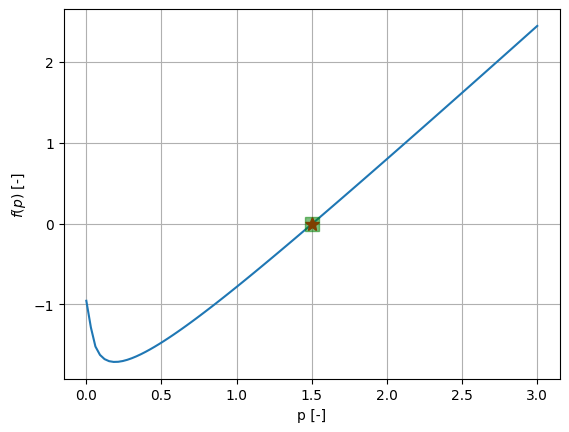

In [33]:
# Inputs
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;
E_star = 3

p = np.linspace(0,3,100)
y = fn(p,E_star,Z,Z0,nj,T)

plt.plot(p,y)
plt.xlabel('p [-]')
plt.ylabel('$f(p)$ [-]')
plt.grid()

# Solve the Equation to get pstar
out = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T))
print('pstar = ', out)

plt.plot(out,0,'r*',markersize=10)


# Use Newton's Method

out = get_pstar(E_star, # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-2, # step for taing numerical derivative
              verbose=True)

plt.plot(out,0,'gs',markersize=10,alpha=0.5)

ni [per cubic m] = 7e+19
nZ [per cubic m] = 3.6e+20
zNe [-] = 4
T [eV] = 26.5
E_star [-] = 813.662
Using fsolve ...
pstar =  [0.04836482]
Using Newtons Method ...
pstar = 0.048, Iterations = 4, Residual = -1e-11


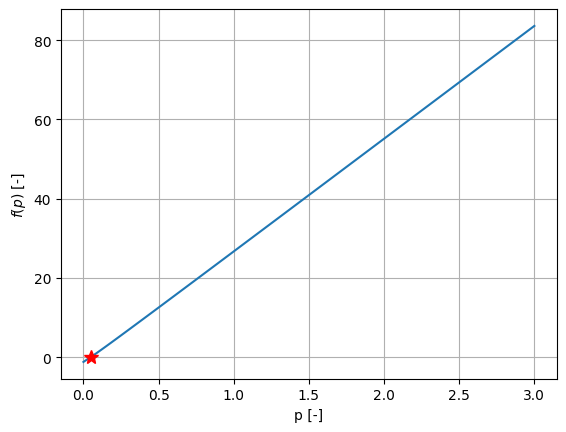

In [34]:
# Randomized Inputs

density_ion =  10**(18 + np.random.rand(1,1).flatten() * 4)[0] # deuterium denisty 1e18 < ni < 1e22 per cubic m
density_Ne =  10**(18 + np.random.rand(1,1).flatten() * 4)[0] # neon denisty 1e18 < ni < 1e22 per cubic m
z_ne = np.random.randint(0,10)
T = 10 + np.random.rand(1,1).flatten()[0] * 40; # eV
E_star = 1 + np.random.rand(1,1).flatten()[0] * 1e3 # Normalized electric field [-]

# Print
print('ni [per cubic m] = %1.2g'%density_ion)
print('nZ [per cubic m] = %1.2g'%density_Ne)
print('zNe [-] = %d'%z_ne)
print('T [eV] = %1.1f'%T)
print('E_star [-] = %1.3f'%E_star)

Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,z_ne]); # Ionization Level
nj = np.array([density_ion,density_Ne]); # Density

p = np.linspace(0,3,100)
y = fn(p,E_star,Z,Z0,nj,T)

plt.plot(p,y)
plt.xlabel('p [-]')
plt.ylabel('$f(p)$ [-]')
plt.grid()

# Solve the Equation to get pstar
out = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T))
print('Using fsolve ...')
print('pstar = ', out)

plt.plot(out,0,'r*',markersize=10)


# Use Newton's Method
print('Using Newton''s Method ...')
out = get_pstar(E_star, # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-3, # step for taking numerical derivative
              verbose=True)

Text(0.5, 1.0, '$n_i, n_{Ne} = 1e+20, 1e+20,\\, T = 10.0 \\, eV$')

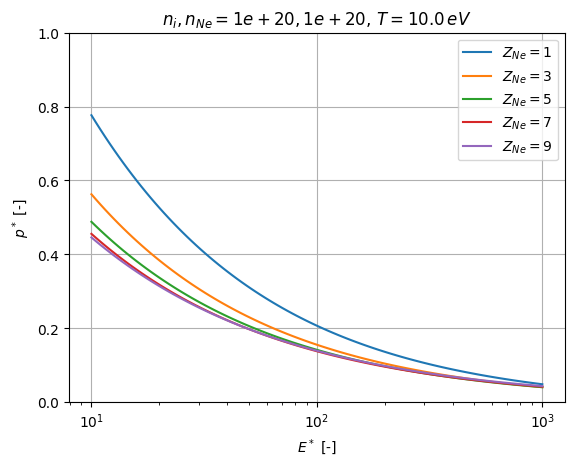

In [35]:
# Vary Estar - Using fsolve

# Constants
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;

# Vary E_star
E_star = np.logspace(1,3,100)
pstar = np.zeros_like(E_star)

for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')


# Now Try different Ne ionizations

Z0 = np.array([1,3]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,5]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,7]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,9]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = fsolve(fn, 1, args=(E_star[ii],Z,Z0,nj,T))
    pstar[ii] = out[0]
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')





plt.xlabel('$E^*$ [-]')
plt.ylabel('$p^*$ [-]')
plt.grid()
plt.xscale('log')
plt.legend()
plt.ylim([0,1])
plt.title('$n_i, n_{Ne} = %1.3g, %1.3g,\, T = %1.1f \, eV$'%(nj[0],nj[1],T))


Text(0.5, 1.0, '$n_i, n_{Ne} = 1e+20, 1e+20,\\, T = 10.0 \\, eV$')

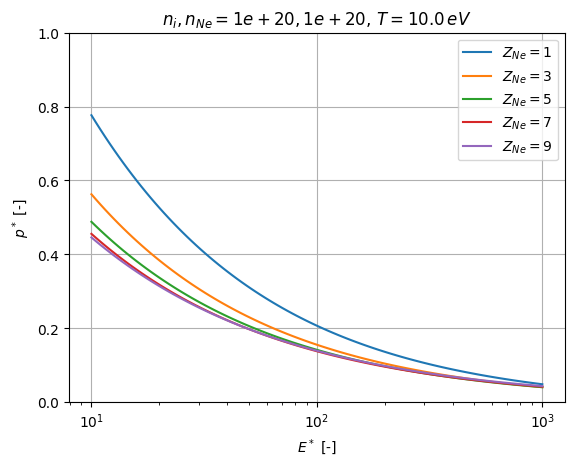

In [36]:
# Vary Estar - using Newton's method

# Constants
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10;

# Vary E_star
E_star = np.logspace(1,3,100)
pstar = np.zeros_like(E_star)

for ii in range(E_star.shape[0]):
    out = get_pstar(E_star[ii], # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-3 # step for taking numerical derivative
              )
    pstar[ii] = out
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')


# Now Try different Ne ionizations

Z0 = np.array([1,3]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = get_pstar(E_star[ii], # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-3 # step for taking numerical derivative
              )
    pstar[ii] = out
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,5]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = get_pstar(E_star[ii], # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-3 # step for taking numerical derivative
              )
    pstar[ii] = out
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,7]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = get_pstar(E_star[ii], # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-3 # step for taking numerical derivative
              )
    pstar[ii] = out
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')

# Now Try different Ne ionizations

Z0 = np.array([1,9]); # Ionization Level
pstar = np.zeros_like(E_star)
for ii in range(E_star.shape[0]):
    out = get_pstar(E_star[ii], # Epar / E_CH (E_CH = Connor Hastie Critical Field)
              Z, # Max. Ionization
              Z0, # Ionization
              nj, # ion density [per cubic m]
              T, # eV
              x0=1, # initial guess
              nmax=100, # max. number of iterations
              eps=1e-3 # step for taking numerical derivative
              )
    pstar[ii] = out
    
plt.plot(E_star,pstar,label='$Z_{Ne} = ' + str(Z0[1]) + '$')





plt.xlabel('$E^*$ [-]')
plt.ylabel('$p^*$ [-]')
plt.grid()
plt.xscale('log')
plt.legend()
plt.ylim([0,1])
plt.title('$n_i, n_{Ne} = %1.3g, %1.3g,\, T = %1.1f \, eV$'%(nj[0],nj[1],T))


# Avalanching Rate

In [70]:

def getHesslowAvalanchingRate(E_star,Z,Z0,nj,T,B=0): # Presently implemnted for Ne, must be implemented for Ar
    # Returns the avalanching rate in per second
    # E_star [-] = Parallel E-field / E_CH (E_CH = Connor Hastie Electric field)
    # Z = max. ionization; first element of array is deuterium, next is Neon
    # Z0 = ionization level; first element of array is 1, next is Neon ionization
    # nj = density of each species [per cubic m]
    # T = temperature [eV]

    ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
    ntot = np.sum(Z * nj) # Bound + Free electron density, per cubic m 
    lnAc = 14.6 + 0.5 * np.log(T / (ne_free/1e20)) # RE-Thermal Coul. log
    Eceff = getEc_eff(Z,Z0,nj,T,B)[0] # Effective E-field, V/m
    pstar = fsolve(fn, 1, args=(E_star,Z,Z0,nj,T))[0] # critical momentum [-]
    nuD, nuS =  get_nuD_nuS(pstar,Z,Z0,nj,T) # Slowing down and deflection freq [-]
    
    ECH = RE.getConnorHastieField(ne_free,RE.getCoulombLog(ne_free,T)) # Connor Hastie Field [V/m]
    Epar = ECH * E_star # Parallel Electric Field V/m
    
    gamma = const.e / (const.m_e * const.c *lnAc) * (ntot / ne_free) * (Epar - Eceff) / np.sqrt(4 + nuS * nuD) # per second
    
    return gamma


## Calculate the avlanching rate and reproduce th figure below  (Note: figure is for Argon)

Eceff [V/m] = 0.88


(0.0, 100.0)

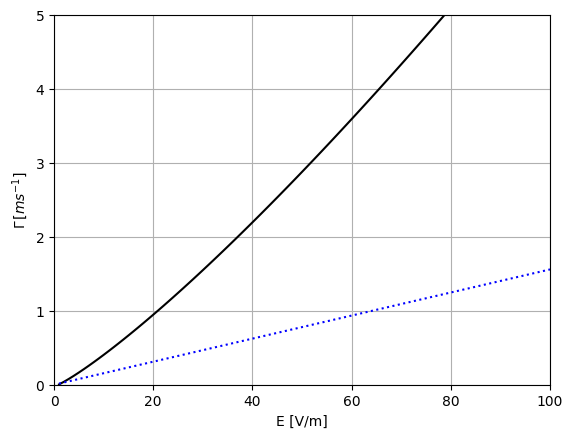

In [74]:
# Inputs

Epar = np.linspace(1,100,100) # V/m
Z = np.array([1,10]); # Max. Ionization
Z0 = np.array([1,1]); # Ionization Level
nj = np.array([1e20,1e20]); # Density
T = 10
B = 0
ne_free = np.sum(Z0 * nj) # Free electron density, per cubic m 
lnA = RE.getCoulombLog(ne_free,T) # Coul. Log
Ec = RE.getConnorHastieField(ne_free,lnA) # V/m 
Eceff = getEc_eff(Z,Z0,nj,T,B)[0] # Effective E-field, V/m
E_star = Epar / Ec

### Print ####
print('Eceff [V/m] = %1.2f'%Eceff)

### Calculate Avalanching Rate ####
gamma = np.zeros_like(E_star)
for ii in range(Epar.shape[0]):
    out = getHesslowAvalanchingRate(E_star[ii],Z,Z0,nj,T,B) # per s
    gamma[ii] = out


plt.plot(Epar,gamma*1e-3,'k-')
plt.xlabel('E [V/m]')
plt.ylabel('$\Gamma \, [ms^{-1}]$')
plt.grid()

# RP Model
nD = nj[0] # per cubic m
ne  = nD 
T = 10 # eV
lnA = RE.getCoulombLog(ne,T)
Ec = RE.getConnorHastieField(ne,lnA) # V/m 
Z = 1
inv_aspect_ratio = 2/6.2

gamma_RP2 = RE.get_avalance_growth_rate_RP2(Epar/Ec,ne,inv_aspect_ratio,lnA,Z) # per s

plt.plot(Epar,gamma_RP2*1e-3,'b:')

plt.ylim([0,5])
plt.xlim([0,100])



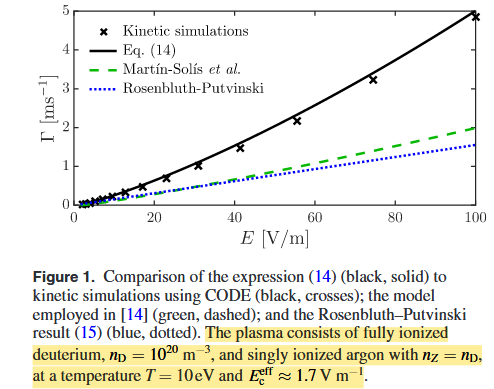